# NuFANCI proteomics: nuclear speckle NuFANCI after Actinomycin D

Speckle NuFANCI and input from DMSO- and Actinomycin D-treated HCT116 cells: protein detection, sample correlation, PCA and clustered heatmap annotated with published nucleolar and speckle lists. The later cells (ranking and volcano) were adapted from experiment 02 and refer to its sample names.

**Inputs** (in the working directory): `combined_protein_f.tsv` (step 00), `experiment_annotation.tsv` and FragPipe-Analyst `DE_results.csv` (step 01); published marker lists in `reference_lists/` (see the module README).

Original notebook: `FANCY_Experriment_NPKL_ActD_AlphaPep_20251006.ipynb`.

In [1]:
from __future__ import print_function
import sys
import os
import pandas as pd
import csv
import seaborn as sns
import time
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import warnings
import numpy as np
import plotly
import plotly.express as px
import plotly.graph_objects as go
from functools import reduce
import scipy
from scipy.spatial import distance
from scipy.cluster import hierarchy
import sklearn
from sklearn.metrics import silhouette_score
from sklearn import cluster, datasets, mixture
from sklearn.neighbors import kneighbors_graph
from string import ascii_letters

np.random.seed(12345)
import matplotlib.pyplot as plt


warnings.filterwarnings("ignore", category=UserWarning, module="openpyxl") # remove warning from mac
import plotly.io as pio
pio.renderers.default = "plotly_mimetype+notebook" 
from IPython.display import display, HTML, Markdown
display(HTML("<style>:root { --jp-notebook-max-width: 80% !important; }</style>"))
from sklearn.utils._openmp_helpers import _openmp_effective_n_threads, _openmp_parallelism_enabled
_openmp_effective_n_threads(6)

plt.rcParams['pdf.fonttype'] = 42
import matplotlib as mpl
mpl.rcParams['font.family'] = 'Arial'

os.environ.setdefault("TF_NUM_THREADS", "10")
os.environ.setdefault("TF_LOOP_PARALLEL_ITERATIONS", "10")

/Users/magalhae/miniforge3/envs/alphastats_dev/lib/python3.10/site-packages/kaleido/_sync_server.py:11: UserWarning:




This means that static image generation (e.g. `fig.write_image()`) will not work.

Please upgrade Plotly to version 6.1.1 or greater, or downgrade Kaleido to version 0.2.1.




'10'

In [2]:
colorway=["#B80000", "#E81E63", "#8D239E", "#673AB7", "#3F51B5", "#253985", "#02A8F4", "#009688", "#8BC34A", "#FF9800", "#FE5622", "#795648", "#9E9E9E", "#617D8B",]

plotly.io.templates["alphastats_colors"] = plotly.graph_objects.layout.Template(
    layout=plotly.graph_objects.Layout(
        paper_bgcolor="rgba(0,0,0,0)",
        plot_bgcolor="rgba(0,0,0,0)",
        colorway=colorway
        ,
    )
)
plotly.io.templates.default = "simple_white+alphastats_colors"

display(Markdown('<br>'.join(
    f'<span style="font-family: monospace">{color} <span style="color: {color}">████████</span></span>'
    for color in colorway
)))
len(colorway)

<span style="font-family: monospace">#B80000 <span style="color: #B80000">████████</span></span><br><span style="font-family: monospace">#E81E63 <span style="color: #E81E63">████████</span></span><br><span style="font-family: monospace">#8D239E <span style="color: #8D239E">████████</span></span><br><span style="font-family: monospace">#673AB7 <span style="color: #673AB7">████████</span></span><br><span style="font-family: monospace">#3F51B5 <span style="color: #3F51B5">████████</span></span><br><span style="font-family: monospace">#253985 <span style="color: #253985">████████</span></span><br><span style="font-family: monospace">#02A8F4 <span style="color: #02A8F4">████████</span></span><br><span style="font-family: monospace">#009688 <span style="color: #009688">████████</span></span><br><span style="font-family: monospace">#8BC34A <span style="color: #8BC34A">████████</span></span><br><span style="font-family: monospace">#FF9800 <span style="color: #FF9800">████████</span></span><br><span style="font-family: monospace">#FE5622 <span style="color: #FE5622">████████</span></span><br><span style="font-family: monospace">#795648 <span style="color: #795648">████████</span></span><br><span style="font-family: monospace">#9E9E9E <span style="color: #9E9E9E">████████</span></span><br><span style="font-family: monospace">#617D8B <span style="color: #617D8B">████████</span></span>

14

In [3]:
Andersen2005 = pd.read_csv('reference_lists/NucleolusList/Andersen2005_idmapping_active_true_2024_08_28.tsv',low_memory=False, sep = '\t')
SubCellBarcode = pd.read_csv('reference_lists/NucleolusList/SubCell_markerProteins_annotated.csv',low_memory=False)
Stenstrom2020 = pd.read_excel('reference_lists/NucleolusList/msb209469-sup-0002-datasetev1.xlsx', sheet_name=1)
Stenstrom2020 = Stenstrom2020[~Stenstrom2020['Uniprot ID'].isna()]
Zhang2025 = pd.read_csv('reference_lists/NucleolusList/Zang2025.csv',low_memory=False)

In [4]:
Dyakov_df = pd.read_excel("reference_lists/Speackle_lists_media-1.xlsx", sheet_name= "1. All term lists")
#Dyakov_df.info()
Dyakov_Paraspeckle_l = Dyakov_df['Paraspeckle curated'].tolist()
GO_nukl_spk_l = Dyakov_df['GO:CC Nuclear speck (GO:0016607)'].tolist()
Dyakov_nukl_spk_l = Dyakov_df['Nuclear speckle curated'].tolist()
Dyakov_CajalBody_l = Dyakov_df['Cajal body curated'].tolist()
Dyakov_HistoneBody_l = Dyakov_df['Histone locus body curated + putative'].tolist()
Dyakov_PML_body_l = Dyakov_df['PML body curated'].tolist()
Dyakov_Polycomb_l = Dyakov_df['Polycomb body curated'].tolist()
Dyakov_NuclearStress_l = Dyakov_df['Nuclear stress body (nSB) curated'].tolist()
Dyakov_Perinucleolar_l = Dyakov_df['Perinucleolar compartment (PNC) curated'].tolist()

Dopie_df = pd.read_excel("reference_lists/Dopie_etall_2020_jcb_201910207_tables1.xlsx", sheet_name= "Speckle ratio(Top 400)")
Dopie_df_l = Dopie_df['Gene names'].tolist()

In [5]:
combined_protein = pd.read_csv('./combined_protein_f.tsv',low_memory=False, sep = '\t')


annot = ["Protein ID", "Entry Name", "Gene", "Protein Length", "Organism", "Protein Existence", "Description"]
## reorder df based on the new order
Hsapiens_Uniprot_annotation = combined_protein.loc[:, annot]
Hsapiens_Uniprot_annotation=Hsapiens_Uniprot_annotation.rename(columns = {'Protein ID':'ProteinID'})
Hsapiens_Uniprot_annotation = Hsapiens_Uniprot_annotation.set_index('ProteinID')
combined_protein=combined_protein.rename(columns = {'Protein ID':'ProteinID'})
combined_protein = combined_protein.set_index('ProteinID')

experiment_annotation = pd.read_csv('./experiment_annotation.tsv', sep = '\t')
experiment_annotation = experiment_annotation.set_index('sample')
            
# DE_results = pd.read_csv('./DE_results.csv',low_memory=False, index_col=0)

Intensity_matrix = combined_protein.filter(regex='Intensity')
Intensity_matrix = Intensity_matrix[Intensity_matrix.columns.drop(list(Intensity_matrix.filter(regex='MaxLFQ')))]
Intensity_matrix.columns = [i.replace(" Intensity", "") for i in Intensity_matrix.columns]

LFQ_matrix = combined_protein.filter(regex='MaxLFQ Intensity')
LFQ_matrix.columns = [i.replace(" MaxLFQ Intensity", "") for i in LFQ_matrix.columns]

# "NSPKL_DMSO_FANCI_2", "NSPKL_DMSO_FANCI_4",

# set the desired order of groups
groups = ["NSPKL_DMSO_Input_1", "NSPKL_DMSO_Input_2", "NSPKL_DMSO_Input_2_1", "NSPKL_DMSO_Input_2_2", "NSPKL_DMSO_Input_2_3",
    "NSPKL_ActD_Input_1", "NSPKL_ActD_Input_2", "NSPKL_ActD_Input_2_2", "NSPKL_ActD_Input_2_3",
           "NSPKL_DMSO_FANCI_3",  "NSPKL_DMSO_FANCI_2_2", "NSPKL_DMSO_FANCI_2_3", "NSPKL_DMSO_FANCI_2", "NSPKL_DMSO_FANCI_4",
          "NSPKL_ActD_FANCI_1", "NSPKL_ActD_FANCI_2", "NSPKL_ActD_FANCI_2_2", "NSPKL_ActD_FANCI_2_3", "NSPKL_ActD_FANCI_3", "NSPKL_ActD_FANCI_4"
         ]

## reorder df based on the new order
LFQ_matrix = LFQ_matrix.loc[:, groups]
LFQ_matrix = LFQ_matrix.loc[(LFQ_matrix!=0).any(axis=1)]
Intensity_matrix = Intensity_matrix.loc[:, groups]
Intensity_matrix = Intensity_matrix.loc[(Intensity_matrix!=0).any(axis=1)]

In [6]:
LFQ_matrix.head()

,NSPKL_DMSO_Input_1,NSPKL_DMSO_Input_2,NSPKL_DMSO_Input_2_1,NSPKL_DMSO_Input_2_2,NSPKL_DMSO_Input_2_3,NSPKL_ActD_Input_1,NSPKL_ActD_Input_2,NSPKL_ActD_Input_2_2,NSPKL_ActD_Input_2_3,NSPKL_DMSO_FANCI_3,NSPKL_DMSO_FANCI_2_2,NSPKL_DMSO_FANCI_2_3,NSPKL_DMSO_FANCI_2,NSPKL_DMSO_FANCI_4,NSPKL_ActD_FANCI_1,NSPKL_ActD_FANCI_2,NSPKL_ActD_FANCI_2_2,NSPKL_ActD_FANCI_2_3,NSPKL_ActD_FANCI_3,NSPKL_ActD_FANCI_4
ProteinID,,,,,,,,,,,,,,,,,,,,
A0A024R1R8,75118.48,930509.56,502700.620,1304034.80,524084.900,197355.73,320646.56,197027.220,1565226.50,404295.4,343484.97,0.0,160748.64,0.0,0.0,287914.12,0.0,229149.16,0.00,0.0
A0A0U1RRE5,0.00,240397.19,89574.805,176270.58,85239.586,0.00,0.00,50614.773,180036.90,0.0,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0
A0A2R8Y4L2,194567.14,216628.53,209682.330,179056.95,230631.330,156005.80,166140.69,147932.300,183152.77,0.0,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,136537.38,0.0
A0AV96,0.00,0.00,27073.210,0.00,25330.887,0.00,0.00,25875.072,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0
A0AVK6,0.00,0.00,13482.547,0.00,4354.137,0.00,0.00,0.000,0.00,0.0,0.00,0.0,0.00,0.0,0.0,0.00,0.0,0.00,0.00,0.0


In [7]:
#Replace 0 with nan
LFQ_matrix_replaced = LFQ_matrix.replace(0, np.nan)
LFQ_matrix_replaced_log = np.log2(LFQ_matrix_replaced + 0.1)

#Quantile normalization
qt = sklearn.preprocessing.QuantileTransformer(random_state=0)
quantile_norm_array = qt.fit_transform(LFQ_matrix_replaced_log.values)
LFQ_matrixQuantile = pd.DataFrame(quantile_norm_array, index=LFQ_matrix_replaced_log.index, columns=LFQ_matrix_replaced_log.columns)


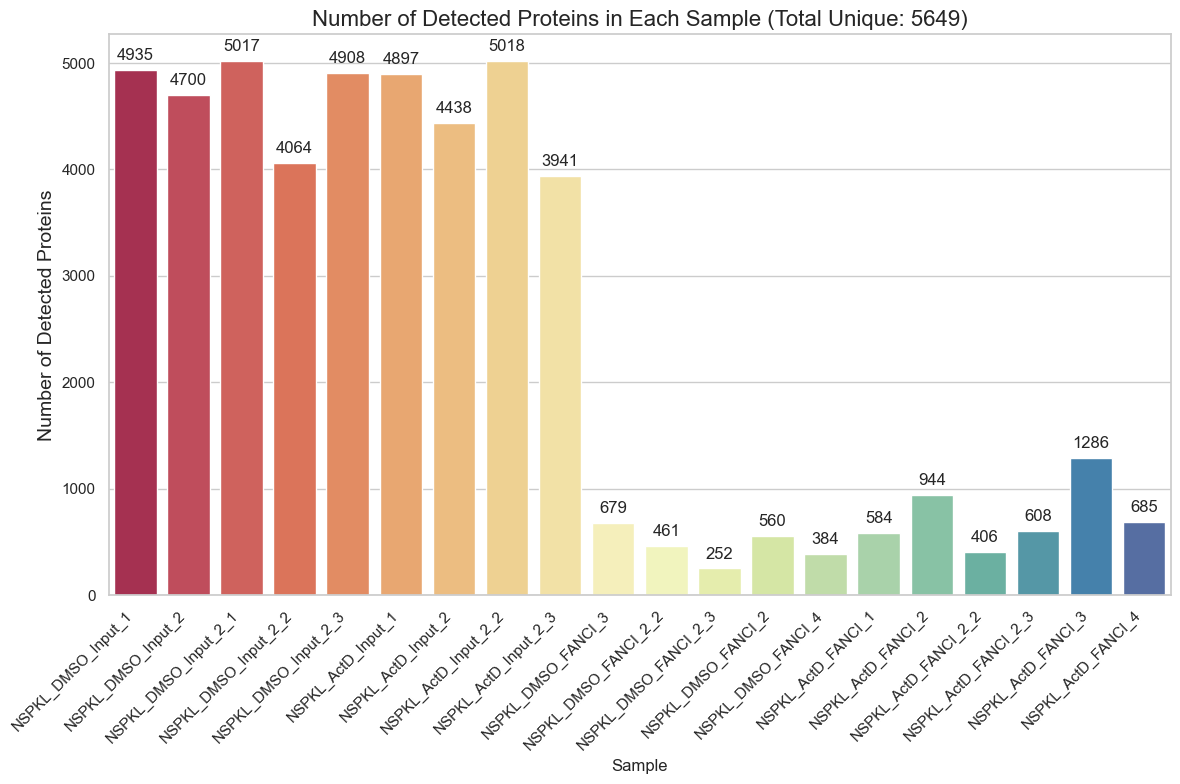

In [8]:
def plot_detected_proteins(expression_data, detection_threshold=0):
    """
    Plot the number of detected proteins in each sample using Seaborn.

    :param expression_data: DataFrame with genes as rows and samples as columns.
    :param detection_threshold: Threshold above which a protein is considered detected.
    """
    # Calculate the number of detected proteins for each sample
    detected_counts = (expression_data > detection_threshold).sum(axis=0)

    # Create a DataFrame for plotting
    plot_data = pd.DataFrame({
        'Sample': detected_counts.index,
        'Detected Proteins': detected_counts.values
    })

    # Plot using Seaborn
    sns.set(style="whitegrid")
    plt.figure(figsize=(12, 8))
    ax = sns.barplot(x='Sample', y='Detected Proteins', data=plot_data, hue = 'Sample', palette='Spectral')

    # Add annotations on top of bars
    for p in ax.patches:
        ax.annotate(
            format(p.get_height(), '.0f'),  # Format number as integer
            (p.get_x() + p.get_width() / 2., p.get_height()),  # Position it at the top of the bar
            ha='center', va='bottom',  # Center alignment
            xytext=(0, 5), textcoords='offset points'  # Offset slightly above the bar
        )

    # Plot title
    title = f'Number of Detected Proteins in Each Sample (Total Unique: {len(expression_data)})'
    plt.title(title, fontsize=16)
    plt.ylabel('Number of Detected Proteins', fontsize=14)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig("Number_of_proteins.pdf")
    plt.show()
    


#### Plot
plot_detected_proteins(LFQ_matrix_replaced)

In [10]:
experiment_annotation

,sample_name,condition,replicate
sample,,,
NSPKL_ActD_FANCI_1,NSPKL_ActD_FANCI_1,NSPKL_ActD_FANCI,1
NSPKL_ActD_FANCI_2,NSPKL_ActD_FANCI_2,NSPKL_ActD_FANCI,2
NSPKL_ActD_FANCI_2_2,NSPKL_ActD_FANCI_2_2,NSPKL_ActD_FANCI,3
NSPKL_ActD_FANCI_2_3,NSPKL_ActD_FANCI_2_3,NSPKL_ActD_FANCI,4
NSPKL_ActD_FANCI_3,NSPKL_ActD_FANCI_3,NSPKL_ActD_FANCI,5
NSPKL_ActD_FANCI_4,NSPKL_ActD_FANCI_4,NSPKL_ActD_FANCI,4
NSPKL_ActD_Input_1,NSPKL_ActD_Input_1,NSPKL_ActD_Input,1
NSPKL_ActD_Input_2,NSPKL_ActD_Input_2,NSPKL_ActD_Input,2
NSPKL_ActD_Input_2_2,NSPKL_ActD_Input_2_2,NSPKL_ActD_Input,3


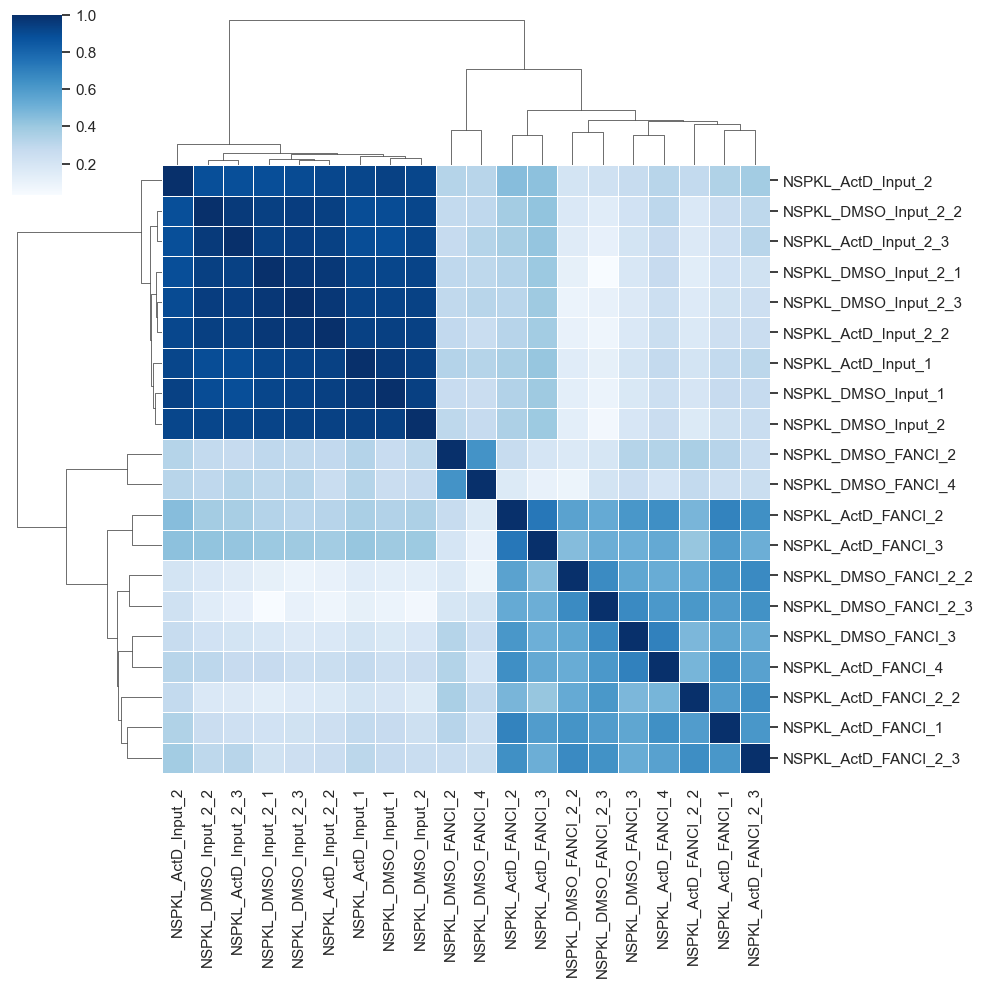

In [11]:
#Correlation Plot
sns.clustermap(LFQ_matrixQuantile.corr(method = 'pearson', numeric_only=True), annot=False,cmap='Blues', linewidths=0.5)
plt.savefig("Correlation_Plot_Normalized_matrix.pdf", bbox_inches='tight')

In [12]:
def gaussian_random_sample_imputation(df, mean_shift=1.8, std_factor=0.3):
    """
    Perform Gaussian random sample imputation on a DataFrame for MS data.

    Parameters:
    df (pd.DataFrame): DataFrame with samples as columns and features as rows. Missing values should be NaN.
    mean_shift (float): The amount to shift the mean of the Gaussian distribution for imputation.
    std_factor (float): Factor to scale the standard deviation of the Gaussian distribution for imputation.

    Returns:
    pd.DataFrame: DataFrame with imputed values.
    """
    # Copy the DataFrame to avoid changing the original
    imputed_df = df.copy()

    # Iterate over each column to perform imputation
    for col in imputed_df.columns:
        # Get the data for the current sample, ignoring NaNs
        valid_data = imputed_df[col].dropna()

        # Calculate the mean and standard deviation for the valid data
        mean_valid = valid_data.mean()
        std_valid = valid_data.std()

        # Calculate the parameters of the normal distribution for imputation
        imputation_mean = mean_valid - mean_shift * std_valid
        imputation_std = std_factor * std_valid

        # Generate imputation values for the missing data
        missing_mask = imputed_df[col].isna()
        num_missing = missing_mask.sum()
        imputed_values = np.random.normal(loc=imputation_mean, scale=imputation_std, size=num_missing)

        # Replace NaN values with the imputed values
        imputed_df.loc[missing_mask, col] = imputed_values

    return imputed_df


In [13]:
imputed_data = gaussian_random_sample_imputation(LFQ_matrixQuantile)

In [14]:
print(np.min(imputed_data))
print(np.max(imputed_data))
print(np.quantile(imputed_data, [0.1, 0.5, 0.90]))

NSPKL_DMSO_Input_1     -0.275274
NSPKL_DMSO_Input_2     -0.344242
NSPKL_DMSO_Input_2_1   -0.316754
NSPKL_DMSO_Input_2_2   -0.327236
NSPKL_DMSO_Input_2_3   -0.335600
NSPKL_ActD_Input_1     -0.308578
NSPKL_ActD_Input_2     -0.295630
NSPKL_ActD_Input_2_2   -0.321361
NSPKL_ActD_Input_2_3   -0.294457
NSPKL_DMSO_FANCI_3     -0.327236
NSPKL_DMSO_FANCI_2_2   -0.324371
NSPKL_DMSO_FANCI_2_3   -0.303825
NSPKL_DMSO_FANCI_2     -0.325638
NSPKL_DMSO_FANCI_4     -0.382531
NSPKL_ActD_FANCI_1     -0.381170
NSPKL_ActD_FANCI_2     -0.327651
NSPKL_ActD_FANCI_2_2   -0.350665
NSPKL_ActD_FANCI_2_3   -0.348462
NSPKL_ActD_FANCI_3     -0.357260
NSPKL_ActD_FANCI_4     -0.294678
dtype: float64
NSPKL_DMSO_Input_1      1.0
NSPKL_DMSO_Input_2      1.0
NSPKL_DMSO_Input_2_1    1.0
NSPKL_DMSO_Input_2_2    1.0
NSPKL_DMSO_Input_2_3    1.0
NSPKL_ActD_Input_1      1.0
NSPKL_ActD_Input_2      1.0
NSPKL_ActD_Input_2_2    1.0
NSPKL_ActD_Input_2_3    1.0
NSPKL_DMSO_FANCI_3      1.0
NSPKL_DMSO_FANCI_2_2    1.0
NSPKL_DMSO_FANCI_

/Users/magalhae/miniforge3/envs/alphastats_dev/lib/python3.10/site-packages/numpy/core/fromnumeric.py:86: FutureWarning:

In a future version, DataFrame.min(axis=None) will return a scalar min over the entire DataFrame. To retain the old behavior, use 'frame.min(axis=0)' or just 'frame.min()'

/Users/magalhae/miniforge3/envs/alphastats_dev/lib/python3.10/site-packages/numpy/core/fromnumeric.py:86: FutureWarning:

In a future version, DataFrame.max(axis=None) will return a scalar max over the entire DataFrame. To retain the old behavior, use 'frame.max(axis=0)' or just 'frame.max()'



In [16]:
df = imputed_data
# df = np.log2(df + 0.1)
df = df.unstack().reset_index()

df.rename(columns={"level_0": "Samples", 0: "Intensity"}, inplace=True)
fig = px.box(df,
                x="Samples",
                y="Intensity"
            )
fig.show(renderer = "png", width=1200, height=600)

ValueError: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido


In [17]:
#PCA

import pandas as pd
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

def plot_pca(df_normalized, df_metadata, save_folder, plot_filename='pca_plot.pdf', n_components=2, x_pc=1, y_pc=2):
    # Fill missing values with 0
    df_normalized_filled = df_normalized.fillna(0)

    # Transpose the filled normalized data frame to have samples as rows and features as columns
    df_normalized_transposed = df_normalized_filled.T

    # Separating out the features
    x = df_normalized_transposed.loc[:, df_normalized_transposed.columns].values

    # Separating out the target
    # y = df.loc[:,['target']].values
    
    x = StandardScaler().fit_transform(x)

    # Ensure the transposed data frame and metadata have the same index (samples)
    # assert df_normalized_transposed.index.equals(df_metadata.index), "Indices of data frames do not match."

    # Perform PCA
    pca = PCA(n_components=n_components)
    principal_components = pca.fit_transform(x)
    # principal_components = pca.fit_transform(df_normalized_transposed)

    # Calculate the explained variance ratio
    explained_variance_ratio = pca.explained_variance_ratio_

    # Create a DataFrame with the PCA results
    pc_columns = [f'PC{i+1}' for i in range(n_components)]
    pca_df = pd.DataFrame(data=principal_components, columns=pc_columns, index=df_normalized_transposed.index)

    # Merge the PCA results with the metadata
    pca_df = pca_df.join(df_metadata['condition'])

    # Validate the specified PCs are within the range of computed components
    if x_pc > n_components or y_pc > n_components:
        raise ValueError(f"Requested principal components exceed the available number ({n_components}).")

    # Plot the specified principal components in a square figure
    plt.figure(figsize=(8, 8))
    sns.scatterplot(data=pca_df, x=f'PC{x_pc}', y=f'PC{y_pc}', hue='condition', palette='Spectral', s=100, alpha=0.7)
    plt.title('PCA of Normalized Data')
    plt.xlabel(f'Principal Component {x_pc} ({explained_variance_ratio[x_pc-1]:.2%} variance)')
    plt.ylabel(f'Principal Component {y_pc} ({explained_variance_ratio[y_pc-1]:.2%} variance)')
    plt.legend(title='Condition')
    plt.grid(True)

    # Save the plot as a PDF in the specified folder
    if not os.path.exists(save_folder):
        os.makedirs(save_folder)
    plt.savefig(os.path.join(save_folder, plot_filename), bbox_inches='tight')
    
    # Show the plot
    plt.show()

    # Return the PCA DataFrame
    return pca_df


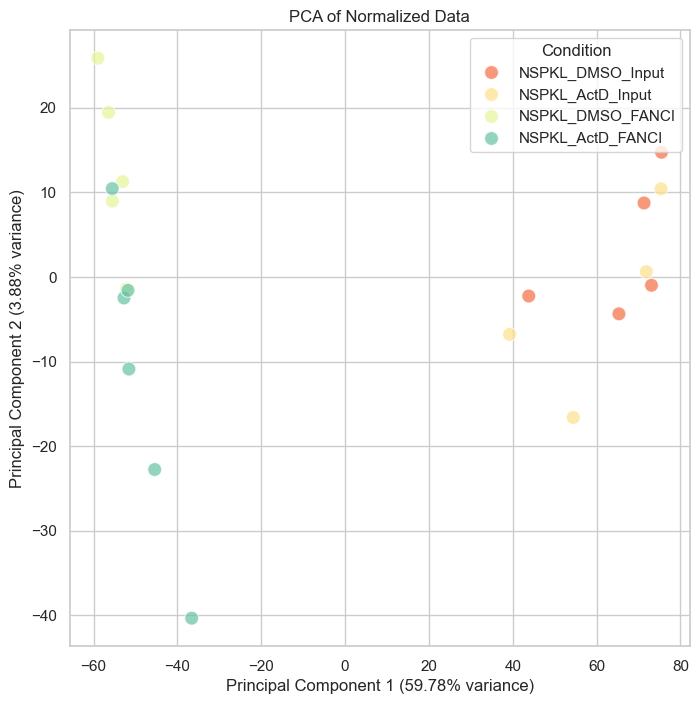

In [18]:
#PCA
pca_df = plot_pca(imputed_data, experiment_annotation, save_folder='./', n_components=5, x_pc=1, y_pc=2)

In [19]:
def element_exists(lst, element):
  # Try to get the index of the element in the list
  try:
    lst.index(element)
  # If the element is found, return True
    return True
  # If a ValueError is raised, the element is not in the list
  except ValueError:
  # Return False in this case
    return False

In [20]:
print(imputed_data.shape)

(5649, 20)


In [21]:
def search(regex: str, df, case=False):
    """Search all the text columns of `df`, return rows with any matches."""
    textlikes = df.select_dtypes(include=[object, "string"])
    return df[
        textlikes.apply(
            lambda column: column.str.contains(regex, regex=True, case=case, na=False)
        ).any(axis=1)
    ]

In [27]:
df = LFQ_matrixQuantile

df = pd.merge(df, Hsapiens_Uniprot_annotation, how="left", left_index=True, right_index=True)


df['Andersen2005'] = df.index.to_series().apply(lambda x: any(i in x for i in Andersen2005['Entry']))
df['SubCellBarcode'] = df.index.to_series().apply(lambda x: any(i in x for i in SubCellBarcode[SubCellBarcode['Compartments']=="N3"]['ProteinID']))
df['SubCellBarcode_N'] = df.index.to_series().apply(lambda x: any(i in x for i in SubCellBarcode[SubCellBarcode['Compartments'].isin(['N1','N2','N3', 'N4'])]['ProteinID']))
df['Stenstrom2020'] = df.index.to_series().apply(lambda x: any(i in x for i in set(Stenstrom2020['Uniprot ID'])))
df['Zhang2025'] = df.index.to_series().apply(lambda x: any(i in x for i in set(Zhang2025['ProteinID'])))

df['Dyakov_Paraspeckle'] = df['Gene'].astype(str).apply(lambda x: any(i in x for i in Dyakov_df['Paraspeckle curated'].astype(str)))
df['Dyakov_nukl_spk'] = df['Gene'].astype(str).apply(lambda x: any(i in x for i in Dyakov_df['Nuclear speckle curated'].astype(str)))
df['Dopie_Top400'] = df['Gene'].astype(str).apply(lambda x: any(i in x for i in Dopie_df['Gene names'].astype(str)))

In [28]:
print(df.Andersen2005.value_counts())
print(df.SubCellBarcode.value_counts())
print(df.Stenstrom2020.value_counts())
print(df.SubCellBarcode_N.value_counts())

print(df.Zhang2025.value_counts())
print(df.Dyakov_Paraspeckle.value_counts())
print(df.Dyakov_nukl_spk.value_counts())
print(df.Dopie_Top400.value_counts())

False    5036
True      613
Name: Andersen2005, dtype: int64
False    5450
True      199
Name: SubCellBarcode, dtype: int64
False    5068
True      581
Name: Stenstrom2020, dtype: int64
False    5036
True      613
Name: SubCellBarcode_N, dtype: int64
False    4666
True      983
Name: Zhang2025, dtype: int64
False    5593
True       56
Name: Dyakov_Paraspeckle, dtype: int64
False    5477
True      172
Name: Dyakov_nukl_spk, dtype: int64
False    5188
True      461
Name: Dopie_Top400, dtype: int64


In [29]:
Anderson2005_df = df.pop("Andersen2005")
SubCellBarcode_df = df.pop("SubCellBarcode")
SubCellBarcode_N_df = df.pop("SubCellBarcode_N")
Stenstrom2020_df = df.pop("Stenstrom2020")

Zhang2025_df = df.pop("Zhang2025")
Dyakov_Paraspeckle_df = df.pop("Dyakov_Paraspeckle")
Dyakov_nukl_spk_N_df = df.pop("Dyakov_nukl_spk")
Dopie_Top400_df = df.pop("Dopie_Top400")

In [30]:
print(np.min(df.iloc[:,:20]))
print(np.max(df.iloc[:,:20]))
print(np.quantile(df.iloc[:,:20].replace(np.nan, 0), [0.1, 0.5, 0.90]))


NSPKL_DMSO_Input_1      0.0
NSPKL_DMSO_Input_2      0.0
NSPKL_DMSO_Input_2_1    0.0
NSPKL_DMSO_Input_2_2    0.0
NSPKL_DMSO_Input_2_3    0.0
NSPKL_ActD_Input_1      0.0
NSPKL_ActD_Input_2      0.0
NSPKL_ActD_Input_2_2    0.0
NSPKL_ActD_Input_2_3    0.0
NSPKL_DMSO_FANCI_3      0.0
NSPKL_DMSO_FANCI_2_2    0.0
NSPKL_DMSO_FANCI_2_3    0.0
NSPKL_DMSO_FANCI_2      0.0
NSPKL_DMSO_FANCI_4      0.0
NSPKL_ActD_FANCI_1      0.0
NSPKL_ActD_FANCI_2      0.0
NSPKL_ActD_FANCI_2_2    0.0
NSPKL_ActD_FANCI_2_3    0.0
NSPKL_ActD_FANCI_3      0.0
NSPKL_ActD_FANCI_4      0.0
dtype: float64
NSPKL_DMSO_Input_1      1.0
NSPKL_DMSO_Input_2      1.0
NSPKL_DMSO_Input_2_1    1.0
NSPKL_DMSO_Input_2_2    1.0
NSPKL_DMSO_Input_2_3    1.0
NSPKL_ActD_Input_1      1.0
NSPKL_ActD_Input_2      1.0
NSPKL_ActD_Input_2_2    1.0
NSPKL_ActD_Input_2_3    1.0
NSPKL_DMSO_FANCI_3      1.0
NSPKL_DMSO_FANCI_2_2    1.0
NSPKL_DMSO_FANCI_2_3    1.0
NSPKL_DMSO_FANCI_2      1.0
NSPKL_DMSO_FANCI_4      1.0
NSPKL_ActD_FANCI_1      1.0
NSPKL

/Users/magalhae/miniforge3/envs/alphastats_dev/lib/python3.10/site-packages/numpy/core/fromnumeric.py:86: FutureWarning:

In a future version, DataFrame.min(axis=None) will return a scalar min over the entire DataFrame. To retain the old behavior, use 'frame.min(axis=0)' or just 'frame.min()'

/Users/magalhae/miniforge3/envs/alphastats_dev/lib/python3.10/site-packages/numpy/core/fromnumeric.py:86: FutureWarning:

In a future version, DataFrame.max(axis=None) will return a scalar max over the entire DataFrame. To retain the old behavior, use 'frame.max(axis=0)' or just 'frame.max()'



In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5649 entries, A0A024R1R8 to Q9Y6Y9
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   NSPKL_DMSO_Input_1    4935 non-null   float64
 1   NSPKL_DMSO_Input_2    4700 non-null   float64
 2   NSPKL_DMSO_Input_2_1  5017 non-null   float64
 3   NSPKL_DMSO_Input_2_2  4064 non-null   float64
 4   NSPKL_DMSO_Input_2_3  4908 non-null   float64
 5   NSPKL_ActD_Input_1    4897 non-null   float64
 6   NSPKL_ActD_Input_2    4438 non-null   float64
 7   NSPKL_ActD_Input_2_2  5018 non-null   float64
 8   NSPKL_ActD_Input_2_3  3941 non-null   float64
 9   NSPKL_DMSO_FANCI_3    679 non-null    float64
 10  NSPKL_DMSO_FANCI_2_2  461 non-null    float64
 11  NSPKL_DMSO_FANCI_2_3  252 non-null    float64
 12  NSPKL_DMSO_FANCI_2    560 non-null    float64
 13  NSPKL_DMSO_FANCI_4    384 non-null    float64
 14  NSPKL_ActD_FANCI_1    584 non-null    float64
 15  NSPKL_ActD_FANC

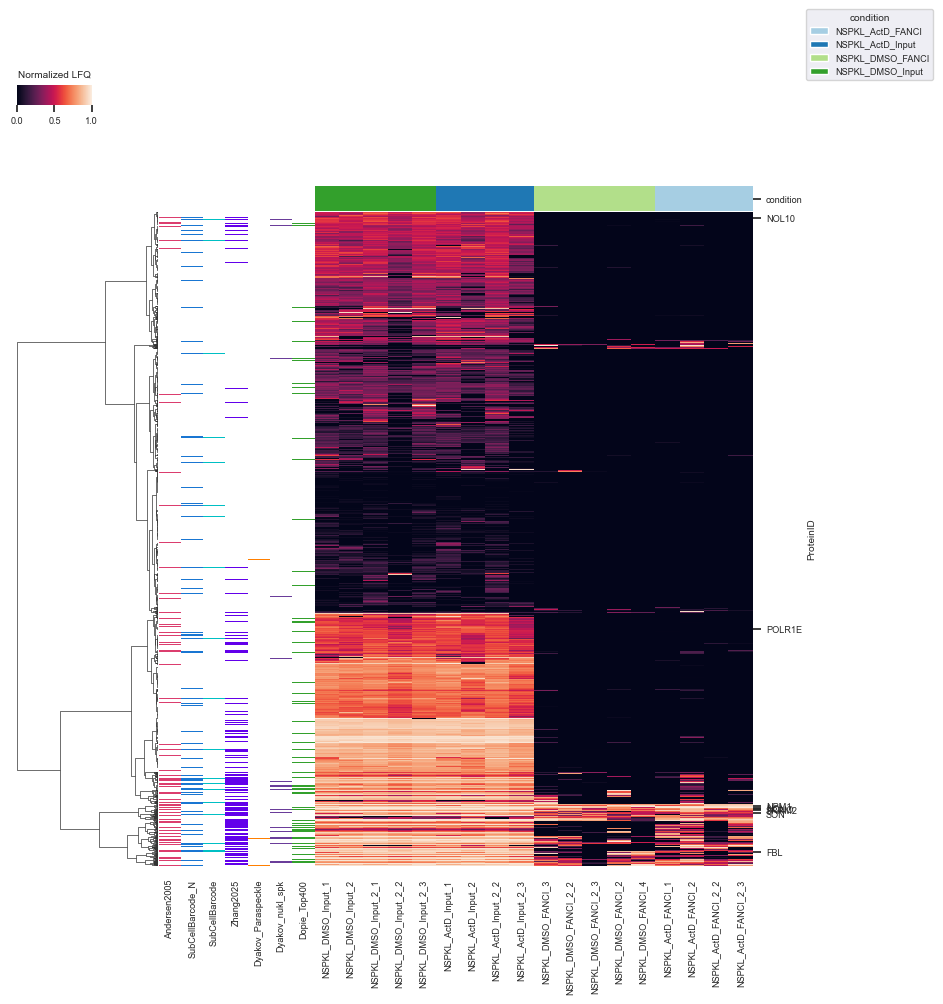

In [32]:
#Plot the reference data

sns.set(font_scale=0.6)

lut1 = dict(zip([True, False], ['#DB3D6E', '#ffffff']))
row_colors1 = Anderson2005_df.map(lut1)

lut2 = dict(zip([True, False], ['#1976D2', '#ffffff']))
row_colors2 = SubCellBarcode_N_df.map(lut2)

lut3 = dict(zip([True, False], ['#00BFC4', '#ffffff']))
row_colors3 = SubCellBarcode_df.map(lut3)

lut4 = dict(zip([ True, False], ['#6200EA', '#ffffff']))
row_colors4 = Zhang2025_df.map(lut4)

lut5 = dict(zip([True, False], ['#ff7f00', '#ffffff']))
row_colors5 = Dyakov_Paraspeckle_df.map(lut5)

lut6 = dict(zip([True, False], ['#6a3d9a', '#ffffff']))
row_colors6 = Dyakov_nukl_spk_N_df.map(lut6)

lut7 = dict(zip([True, False], ['#33a02c', '#ffffff']))
row_colors7 = Dopie_Top400_df.map(lut7)

row_colors = pd.concat([row_colors1,row_colors2,row_colors3,row_colors4,row_colors5,
                        row_colors6,row_colors7
                       ],axis=1)

# Create a color palette for the groups

unique_groups = experiment_annotation['condition'].unique()
palette = sns.color_palette("Paired", len(unique_groups))
group_colors = dict(zip(unique_groups, palette))

# Map colors to the DataFrame for column colors
col_colors = experiment_annotation['condition'].map(group_colors)

#Plot the heatmap
heat_clust = sns.clustermap(df.iloc[:,0:18].replace(np.nan, 0),
                            col_cluster=False,
                            yticklabels=False,
                            method='ward',
                            cmap="rocket",
                             vmin=0,
                             vmax=1,
                            metric='seuclidean',
                            row_colors=row_colors,
                            col_colors=col_colors,
                            cbar_kws=dict(
                                ticks=[0,0.5, 1],
                                orientation="horizontal",  
                            )
                           )

x0, _y0, _w, _h = heat_clust.cbar_pos
heat_clust.ax_cbar.set_position([x0,
                                 0.9,
                                 heat_clust.ax_row_dendrogram.get_position().width/2,
                                 0.02]
                               )
heat_clust.ax_cbar.set_title('Normalized LFQ')
heat_clust.ax_cbar.tick_params(axis='x',
                               length=5)


#### Labels

reordered_labels = df.index[heat_clust.dendrogram_row.reordered_ind].tolist()
use_labels = []


use_labels = ['P06748', #NPM1
              'Q9BSC4', #NOL10
              'P22087', #FBL
              'Q9GZS1', #POLR1E
              'P19338', #NCL
              'P18583', #SON
              'Q9UQ35', #SRRM2
              'Q15233', #NONO
             ]

use_labels_correct = []
use_labels_g = []
use_labels_c = []
for labels in use_labels:
    use_labels_correct.append(search(labels, df.reset_index(), case=False)['ProteinID'].values[0])

for labels in use_labels_correct:
    if labels in reordered_labels:
        use_labels_c.append(labels)
        use_labels_g.append(df.loc[[labels], "Gene"].values[0].split(";")[0])
    else: continue


use_ticks = [reordered_labels.index(label) + .5 for label in use_labels_c]

heat_clust.ax_heatmap.set(yticks=use_ticks, yticklabels=use_labels_g)


# Create custom legend
handles = [Patch(facecolor=group_colors[name], edgecolor='w', label=name) for name in unique_groups]

# Add the legend to the plot
plt.legend(handles=handles, title='condition', bbox_to_anchor=(1, 1), bbox_transform=plt.gcf().transFigure, loc='upper left')

heat_clust.fig.set_size_inches((8,10))

heat_clust.savefig("Heatmap_clustered_NPM1_SRRM2_FANCI_log_qualite.pdf", format = 'pdf')
heat_clust.savefig("Heatmap_clustered_NPM1__SRRM2_FANCI_log_qualite.png", format = 'png', dpi = 300)

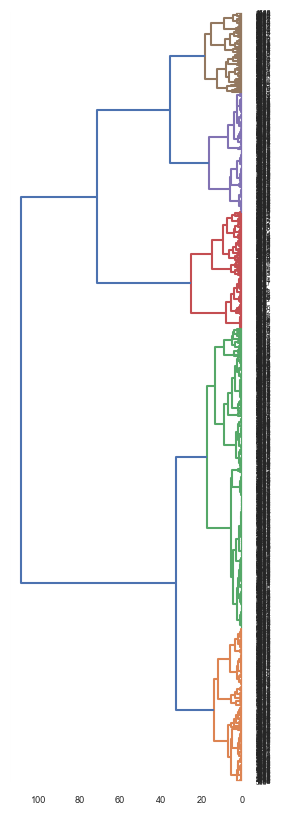

In [37]:
plt.figure(figsize=(3,10))
den = scipy.cluster.hierarchy.dendrogram(heat_clust.dendrogram_row.linkage,
                                         #labels = list(heat_clust.data2d.index),
                                         orientation='left',
                                         color_threshold = 30,
                                         get_leaves = True
                                         )

plt.savefig('den_Heatmap_clustered_NPM1_SRRM2_FANCI_log_qualite.png', format='png', bbox_inches='tight')
plt.savefig('den_Heatmap_clustered_NPM1_SRRM2_FANCI_log_qualite.pdf', format='pdf', bbox_inches='tight')

In [40]:
labels = heat_clust.ax_heatmap.yaxis.get_majorticklabels()
ordered_row_df_heat = heat_clust.data2d
row_order = heat_clust.data2d.index

In [41]:
#extract ivl list (order of the dendrogram), leaves_color_list (cluster)
ordered_row_df_heat.insert(0 , "cluster", den["leaves_color_list"])
ordered_row_df_heat.insert(1 ,'order', np.arange(len(df)))
ordered_row_df_heat.insert(2 , "original_index", den["ivl"])
ordered_row_df_heat = ordered_row_df_heat.iloc[:,0:3]
ordered_row_df_heat.head()

ValueError: cannot insert cluster, already exists

In [42]:
# DE_results.info()

DE_groups = ["NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_log2 fold change",
             "NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.val",
             "NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.adj",
             "NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_significant"
]

In [43]:
ordered_row_df_heat = pd.merge(ordered_row_df_heat, Hsapiens_Uniprot_annotation, how="left", left_index=True, right_index=True)
ordered_row_df_heat['Andersen2005'] = ordered_row_df_heat.index.to_series().apply(lambda x: any(i in x for i in Andersen2005['Entry']))
ordered_row_df_heat['SubCellBarcode'] = ordered_row_df_heat.index.to_series().apply(lambda x: any(i in x for i in SubCellBarcode[SubCellBarcode['Compartments']=="N3"]['ProteinID']))
ordered_row_df_heat['SubCellBarcode_N'] = ordered_row_df_heat.index.to_series().apply(lambda x: any(i in x for i in SubCellBarcode[SubCellBarcode['Compartments'].isin(['N1','N2','N3', 'N4'])]['ProteinID']))
ordered_row_df_heat['Stenstrom2020'] = ordered_row_df_heat.index.to_series().apply(lambda x: any(i in x for i in set(Stenstrom2020['Uniprot ID'])))
ordered_row_df_heat['Zhang2025'] = ordered_row_df_heat.index.to_series().apply(lambda x: any(i in x for i in set(Zhang2025['ProteinID'])))
ordered_row_df_heat = pd.merge(ordered_row_df_heat, DE_results[DE_groups], how="left", left_index=True, right_index=True)
ordered_row_df_heat['Dyakov_Paraspeckle'] = ordered_row_df_heat['Gene'].astype(str).apply(lambda x: any(i in x for i in Dyakov_df['Paraspeckle curated'].astype(str)))
ordered_row_df_heat['Dyakov_nukl_spk'] = ordered_row_df_heat['Gene'].astype(str).apply(lambda x: any(i in x for i in Dyakov_df['Nuclear speckle curated'].astype(str)))
ordered_row_df_heat['Dopie_Top400'] = ordered_row_df_heat['Gene'].astype(str).apply(lambda x: any(i in x for i in Dopie_df['Gene names'].astype(str)))

In [45]:
ordered_row_df_heat.to_csv('NUCL_NPKL_FANCI_Input_ordered_row_df_heatmap_wClustering_Total.csv', index=True)

In [ ]:
##### rank proteins CENTER

In [46]:
LFQ_matrix_log = LFQ_matrix_replaced_log.replace(np.nan, 0 ).transpose()
LFQ_matrix_log = LFQ_matrix_log.join(experiment_annotation).drop('sample_name', axis=1).drop('replicate', axis=1).groupby('condition').mean().transpose().add_suffix('_LFQ_log')
Intensity_matrix = Intensity_matrix.transpose().join(experiment_annotation).drop('sample_name', axis=1).drop('replicate', axis=1).groupby('condition').mean().transpose().add_suffix('_Intencity')

In [47]:
rank_merge = pd.merge(LFQ_matrix_log, Intensity_matrix, how="left", left_index=True, right_index=True)
# rank_merge = rank_merge[rank_merge[['NUCL_GFPNPM1_AB_FANCI_LFQ_log', 'NUCL_GFPNPM1_AB_FANCI_Intencity']].ne(0).all(axis=1)]

In [48]:
rank_merge.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2075 entries, A0A024R1R8 to Q9Y6X9
Data columns (total 4 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   NPKL_SRRM2_Ab_FANCI_LFQ_log    2075 non-null   float64
 1   NUCL_NPM1_AB_FANCI_LFQ_log     2075 non-null   float64
 2   NPKL_SRRM2_Ab_FANCI_Intencity  2075 non-null   float64
 3   NUCL_NPM1_AB_FANCI_Intencity   2075 non-null   float64
dtypes: float64(4)
memory usage: 81.1+ KB


In [49]:
rank_merge["NPKL_SRRM2_Ab_FANCI_Intencity_ranked"] = rank_merge["NPKL_SRRM2_Ab_FANCI_Intencity"].sort_values(ascending=False).rank(ascending=False, method = "first")
rank_merge["NUCL_NPM1_AB_FANCI_Intencity_ranked"] = rank_merge["NUCL_NPM1_AB_FANCI_Intencity"].sort_values(ascending=False).rank(ascending=False, method = "first")

In [50]:
rank_merge = pd.merge(rank_merge, ordered_row_df_heat,left_index=True, right_index=True)

In [40]:
# rank_merge['Andersen2005'] = rank_merge.index.to_series().apply(lambda x: any(i in x for i in Andersen2005['Entry']))
# rank_merge['SubCellBarcode'] = rank_merge.index.to_series().apply(lambda x: any(i in x for i in SubCellBarcode[SubCellBarcode['Compartments']=="N3"]['ProteinID']))
# rank_merge['Stenstrom2020'] = rank_merge.index.to_series().apply(lambda x: any(i in x for i in set(Stenstrom2020['Uniprot ID'])))
# ordered_row_df_heat['Dyakov_nukl_spk'] = ordered_row_df_heat['Gene'].astype(str).apply(lambda x: any(i in x for i in Dyakov_df['Nuclear speckle curated'].astype(str)))
# ordered_row_df_heat['Dopie_Top400'] = ordered_row_df_heat['Gene'].astype(str).apply(lambda x: any(i in x for i in Dopie_df['Gene names'].astype(str)))

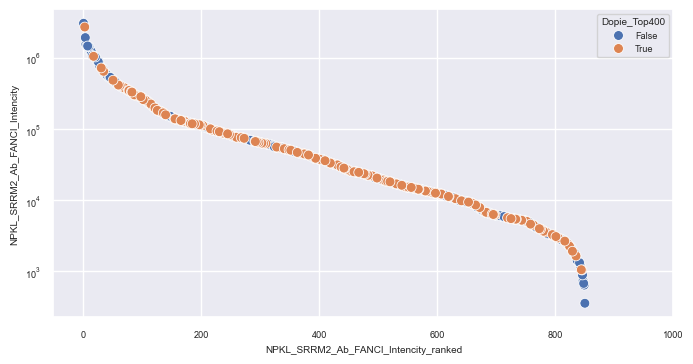

In [51]:
plt.figure(figsize=(8, 4))
g = sns.scatterplot(data = rank_merge.sort_values(by=['Dopie_Top400'], ascending=True),
    x="NPKL_SRRM2_Ab_FANCI_Intencity_ranked",
    y="NPKL_SRRM2_Ab_FANCI_Intencity",
    hue="Dopie_Top400",
    s=50,
    edgecolor='w',
)
g.set_yscale("log")
g.set(xlim=(-50, 1000))
# plt.show()
plt.savefig("NPKL_SRRM2_AB_FANCI_Intencity_Dopie_Top400.pdf", format = 'pdf')

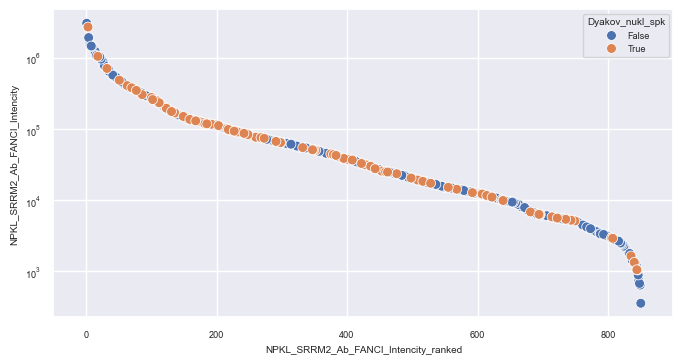

In [52]:
plt.figure(figsize=(8, 4))
g = sns.scatterplot(data = rank_merge.sort_values(by=['Dyakov_nukl_spk'], ascending=True),
    x="NPKL_SRRM2_Ab_FANCI_Intencity_ranked",
    y="NPKL_SRRM2_Ab_FANCI_Intencity",
    hue="Dyakov_nukl_spk",
    s=50,
    edgecolor='w',
)
g.set_yscale("log")
g.set(xlim=(-50, 900))
# plt.show()
plt.savefig("NPKL_SRRM2_AB_FANCI_Intencity_Dyakov_nukl_spk.pdf", format = 'pdf')

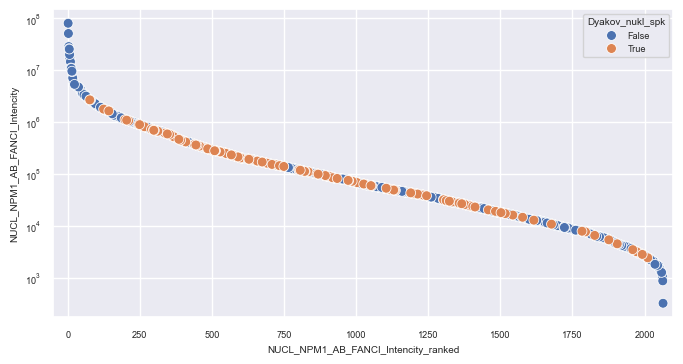

In [53]:
plt.figure(figsize=(8, 4))
g = sns.scatterplot(data = rank_merge.sort_values(by=['Dyakov_nukl_spk'], ascending=True),
    x="NUCL_NPM1_AB_FANCI_Intencity_ranked",
    y="NUCL_NPM1_AB_FANCI_Intencity",
    hue="Dyakov_nukl_spk",
    s=50,
    edgecolor='w',
)
g.set_yscale("log")
g.set(xlim=(-50, 2100))
# plt.show()
plt.savefig("NUCL_NPM1_AB_FANCI_Intencity_ranked_Dyakov_nukl_spk.pdf", format = 'pdf')

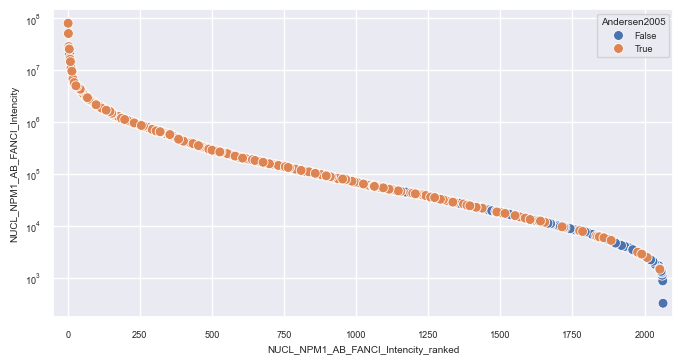

In [56]:
plt.figure(figsize=(8, 4))
g = sns.scatterplot(data = rank_merge.sort_values(by=['Andersen2005'], ascending=True),
    x="NUCL_NPM1_AB_FANCI_Intencity_ranked",
    y="NUCL_NPM1_AB_FANCI_Intencity",
    hue="Andersen2005",
    s=50,
    edgecolor='w',
)
g.set_yscale("log")
g.set(xlim=(-50, 2100))
# plt.show()
plt.savefig("NUCL_NPM1_AB_FANCI_Intencity_ranked_Andersen2005.pdf", format = 'pdf')

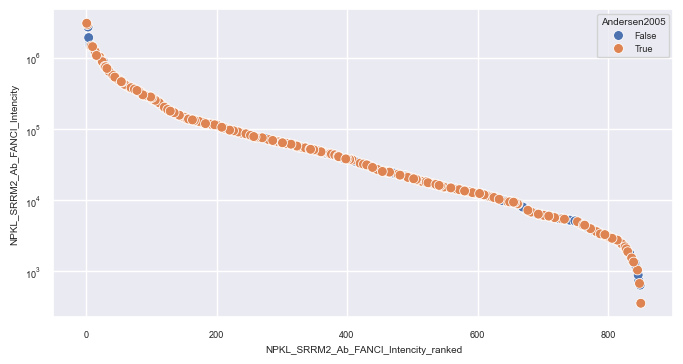

In [57]:
plt.figure(figsize=(8, 4))
g = sns.scatterplot(data = rank_merge.sort_values(by=['Andersen2005'], ascending=True),
    x="NPKL_SRRM2_Ab_FANCI_Intencity_ranked",
    y="NPKL_SRRM2_Ab_FANCI_Intencity",
    hue="Andersen2005",
    s=50,
    edgecolor='w',
)
g.set_yscale("log")
g.set(xlim=(-50, 900))
# plt.show()
plt.savefig("NPKL_SRRM2_Ab_FANCI_Intencity_ranked_Andersen2005.pdf", format = 'pdf')

In [58]:
rank_merge.to_csv('NUCL_FANCI_Input_rankedProteins.csv', index=True)


In [59]:
toMerge = rank_merge.loc[:, ["NUCL_NPM1_AB_FANCI_Intencity_ranked", "NPKL_SRRM2_Ab_FANCI_Intencity_ranked"]]

In [60]:
ordered_row_df_heat = pd.merge(ordered_row_df_heat, toMerge, how="left", left_index=True, right_index=True)
ordered_row_df_heat.to_csv('NUCL_FANCI_Input_ordered_row_df_heatmap_wClustering_Total_kanked.csv', index=True)

In [61]:
DE_groups

['NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_log2 fold change',
 'NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.val',
 'NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.adj',
 'NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_significant']

/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_58699/901763012.py:9: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_58699/901763012.py:10: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

/var/folders/dd/83fsp94d6_98_nzr92wk_nt5nn0dv6/T/ipykernel_58699/901763012.py:13: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the do

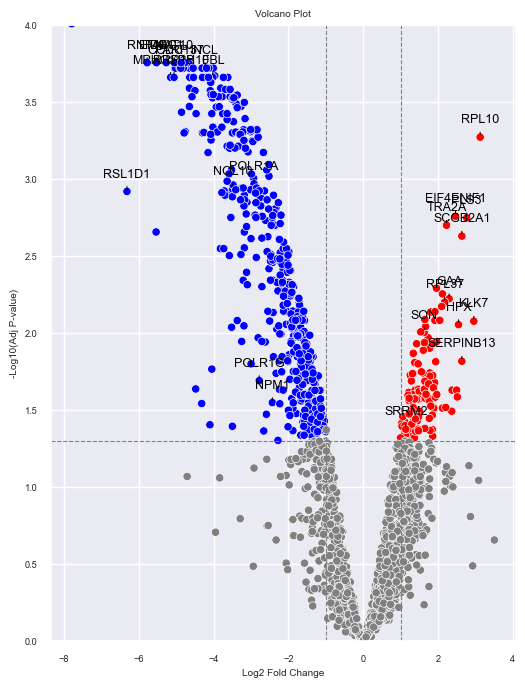

In [89]:
#Volcano Plot
plt.rcParams['pdf.fonttype'] = 42
mpl.rcParams['font.family'] = 'Arial'


df = DE_results[['Gene Name', 'NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_log2 fold change', 'NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.adj']]

# Calculate -log10(pvalue)
df['neg_log10_pvalue'] = -np.log10(df['NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.adj'])
df['log2FoldChange']= df['NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_log2 fold change']

# color positive and negative DEGs with different colors
df["color"] = np.where(
    (df["NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.adj"] < 0.05) & (df["log2FoldChange"] >= 1), "red",
    np.where(
        (df["NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_p.adj"] < 0.05) & (df["log2FoldChange"] <= -1), "blue",
        "grey"
    )
)


# Lists for custom highlighting and labeling
highlight_genes = DE_results[DE_results['NPKL_SRRM2_Ab_FANCI_vs_NUCL_NPM1_AB_FANCI_significant']==True].index.values

# # Sort by absolute log2FoldChange and p-value to find top 10 genes
# df['ranking'] = df['log2FoldChange'].abs() * df['neg_log10_pvalue']
# df_top = df.nlargest(10, 'ranking')
n = 10  # number of labels for each side
# Add ranking metric
df['ranking'] = df['log2FoldChange'].abs() * df['neg_log10_pvalue']

# Top positive
df_top_pos = df[df['log2FoldChange'] > 0].nlargest(n, 'ranking')

# Top negative
df_top_neg = df[df['log2FoldChange'] < 0].nlargest(n, 'ranking')

# Combine
df_top = pd.concat([df_top_pos, df_top_neg])

label_genes = ["NPM1", "SON", "SRRM2", "NCL", "NOL10", "FBL", "POLR1G", "POLR1A"]
rows_to_add = df[df["Gene Name"].isin(label_genes)]
df_top = pd.concat([df_top, rows_to_add], ignore_index=True)

# Define custom colors
colors = ['grey' if gene not in highlight_genes else '#1f78b4' for gene in df.index]

# Create the plot
plt.figure(figsize=(6, 8))
ax = sns.scatterplot(data=df, x='log2FoldChange', y='neg_log10_pvalue', hue="color", palette={"red": "red", "blue": "blue", "grey": "grey"}, legend=False)

# # Add labels to specific genes
# for i, row in df.iterrows():
#     if row['Protein ID'] in label_genes:
#         plt.annotate(row['Protein ID'], (row['log2FoldChange'], row['neg_log10_pvalue']),
#                      textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, color='black')

# Add labels to the top 10 genes
for i, row in df_top.iterrows():
    plt.annotate(row['Gene Name'], (row['log2FoldChange'], row['neg_log10_pvalue']),
                 textcoords="offset points",
                 xytext=(0,10),
                 ha='center',
                 fontsize=9,
                 color='black',
                 arrowprops=dict(arrowstyle="-",
                                 color="black",
                                 lw=0.8))

# Add reference lines for significance thresholds
plt.axhline(y=-np.log10(0.05), color='grey', linestyle='--', linewidth=0.8)
plt.axvline(x=1, color='grey', linestyle='--', linewidth=0.8)
plt.axvline(x=-1, color='grey', linestyle='--', linewidth=0.8)

# Customize plot labels and title
plt.xlabel('Log2 Fold Change')
plt.ylabel('-Log10(Adj P-value)')
plt.title('Volcano Plot')
plt.grid(True)
ax.set(ylim=(0, 4))

plt.savefig('Volcano_NPKL_vs_NUCL.pdf')

plt.show()

In [94]:
df.to_csv('Volcano_NPKL_vs_NUCL_Data.csv', index=True)